# Exercise B
## Turning your time-dependent model into a Gammapy model

This notebook adapts [this gammapy tutorial](https://docs.gammapy.org/2.1/tutorials/analysis-3d/event_sampling_nrg_depend_models.html#create-the-energy-dependent-temporal-model) but instead of different PowerLaw models, we will use a GAMERA model

## A note on units
Units in GAMERA are mostly in cgs, with several exceptions that are meaningful in the astrophysical context.

    times are in years, except for particle escape time scales
    lengths are in parsecs
    when retrieving SEDs, for convenience the units are
        erg / s / cm2 vs TeV for radiation flux SEDs
        erg / s vs. TeV for luminosity SEDs (i.e. when the distance to the source is not set)
        erg vs. TeV for particle SEDs

    (differential spectra are again in cgs units)
    gas densities are in number densities.

Also, the units of the spectrum will impact the unit of the calculated radiation spectra. For instance, if the unit of the particle spectrum is only differential in energy, i.e. 1/erg, the output radiation spectra will have the unit of a flux if a source distance is specified (see below) or differential photon count per energy and time if not.

On the other hand, if the input unit is differential also in volume, i.e. 1/erg/cm3, then also the output radiation spectrum will be. Therefore, if no distance is specified in this case, a volume photon emissivity will be calculated, i.e. d3N/dEdVdt.

In [1]:
import gappa as gp
import numpy as np
import astropy.units as u
from gammapy.maps import MapAxis
import matplotlib.pyplot as plt


## We will use the temporal model which we constructed in exercise A and turn it into a Gammapy time-dependent model

Using the same B field definition

In [2]:
def B_field(t,a, t0, B0):
    return (a*(t0/t)*B0).to('G')

# Define array of times
times = np.linspace(1,100,100)*u.day 

# Calculate B
B = B_field(times,1, 1*u.day, 1e-1*u.G)

# Construct lookup
B_field_lookup = np.array(list(zip(times.to_value('yr'), B.to_value('G'))))


and the same particle spectrum

In [3]:
# A method to create a power-law with a cutoff which we will inject continuously
def define_injected_spectrum(index=2, 
                             E_min=0.1*u.TeV, 
                             E_max=2*u.PeV, 
                             luminosity=1e36*u.erg/u.s, 
                             E_cut=100*u.TeV,
                             Nbins=50):
    "A power-law with an exponential cutoff"
    energy_electrons = MapAxis.from_energy_bounds(energy_min=E_min, energy_max=E_max, nbin=Nbins)
    exp_cutoff = np.exp(-(energy_electrons.center.to('erg')/E_cut.to('erg')).value)
    power_law = (energy_electrons.center.to_value('erg') ** -index)*exp_cutoff

    # Normalize to total power (this is not really needed but we use it for the plot)
    fu = gp.Utils()
    integral = fu.Integrate(list(zip(energy_electrons.center.to_value('erg'), power_law * energy_electrons.center.to_value('erg'))))
    power_law *= luminosity.to_value('erg s-1') / integral 
    #################################################################################

    
    # Bundle together in the way GAMERA wants
    power_law_spectrum = np.array(list(zip(energy_electrons.center.to_value('erg'), power_law)))

    return power_law_spectrum

we now put it all together into one function

In [4]:
def photon_spectrum_at_t(t=10*u.day, photon_energies=np.logspace(-16,3,200)*u.TeV):
    # Set up the Particles class
    fp = gp.Particles()
    fp.ToggleQuietMode()

    # Provide B field lookup
    fp.SetBField(B_field_lookup)

    # Set CMB
    fp.AddThermalTargetPhotons(2.7,0.255*gp.eV_to_erg)

    # Change minimum time
    tmin = times[0].to_value('yr')/2
    fp.SetTmin(tmin)

    # Set injected spectrum
    power_law_spectrum = define_injected_spectrum()
    fp.SetCustomInjectionSpectrum(power_law_spectrum)

    # change t to years
    t = t.to_value('yr')
    print("Time", t)

    # Set Age to t
    fp.SetAge(t)

    # CalculateElectronSpectrum
    fp.CalculateElectronSpectrum()

    # Set up radiation class 
    fr = gp.Radiation()
    fr.ToggleQuietMode()

    # Add CMB to ThermalTargetPhotons
    fr.AddThermalTargetPhotons(2.7,0.255*gp.eV_to_erg)

    # Set distance
    distance = 1*u.kpc
    fr.SetDistance(distance.to_value('pc'))


    # Get B field at this time and set it
    B = fp.GetBField(t)
    fr.SetBField(B)

    # SetElectrons
    fr.SetElectrons(fp.GetParticleSpectrum())

    # compute the spectrum on the points
    fr.CalculateDifferentialPhotonSpectrum(photon_energies.to_value('erg'))

    total_sed = np.asarray(fr.GetTotalSED())
    
    # if the energy requested is outside of the range of the SEDs we just return 0
    if len(total_sed)==0:
        return np.zeros(len(photon_energies))*u.cm**-2*u.eV**-1*u.s**-1

    sed = total_sed[:,1]

    # Get back to the world of units
    sed *= u.erg * u.cm**-2 *u.s **-1

    result = (sed / ((total_sed[:,0]*u.TeV) ** 2)).to("1 / (cm2 eV s)")
    result = np.reshape(result, photon_energies.shape)
    return result

In [5]:
photon_spectrum_at_t()

Time 0.02737850787132101


<Quantity [5.69854427e+02, 4.92142742e+02, 4.25025402e+02, 3.67058093e+02,
           3.16993401e+02, 2.73753971e+02, 2.36409323e+02, 2.04155828e+02,
           1.76299416e+02, 1.52240636e+02, 1.31461763e+02, 1.13515649e+02,
           9.80161090e+01, 8.46296033e+01, 7.30680648e+01, 6.30826978e+01,
           5.44586245e+01, 4.70102615e+01, 4.05773256e+01, 3.50213848e+01,
           3.02228795e+01, 2.60785495e+01, 2.24992121e+01, 1.94078427e+01,
           1.67379175e+01, 1.44319821e+01, 1.24404147e+01, 1.07203588e+01,
           9.23480055e+00, 7.95177272e+00, 6.84366653e+00, 5.88663774e+00,
           5.06009364e+00, 4.34625000e+00, 3.72974860e+00, 3.19732694e+00,
           2.73753309e+00, 2.34047964e+00, 1.99763133e+00, 1.70162192e+00,
           1.44609623e+00, 1.22557410e+00, 1.03533305e+00, 8.71307403e-01,
           7.30001126e-01, 6.08412694e-01, 5.03969763e-01, 4.14471922e-01,
           3.38039666e-01, 2.73067857e-01, 2.18182028e-01, 1.72196286e-01,
           1.34072238e-01

### From now the steps are fully following [this gammapy tutorial](https://docs.gammapy.org/2.1/tutorials/analysis-3d/event_sampling_nrg_depend_models.html#create-the-energy-dependent-temporal-model) but adapted to our case

Define a RegionNDMap

In [6]:
from gammapy.maps import RegionNDMap
from regions import PointSkyRegion
from astropy.coordinates import SkyCoord
from astropy.time import Time
from gammapy.modeling.models import LightCurveTemplateTemporalModel

In [7]:
# Source position
pointing_position = SkyCoord("0 deg", "0 deg", frame="icrs")

# Time axis between 1 and 100 days
time_axis = MapAxis.from_bounds(1 * u.day, 100 * u.day, nbin=5, name="time", interp="lin")

# Energy axis between 0.2 and 100 TeV
energy_axis = MapAxis.from_energy_bounds(
    energy_min=0.2 * u.TeV, energy_max=100 * u.TeV, nbin=10
)


# RegionNDMap
m = RegionNDMap.create(
    region=PointSkyRegion(center=pointing_position),
    axes=[energy_axis, time_axis],
    unit="cm-2s-1TeV-1",
)

to compute the spectra as a function of time we extract the coordinates of the geometry

In [8]:
coords = m.geom.get_coord(sparse=True)

evaluate the spectra and fill the RegionNDMap

In [9]:
energies = coords["energy"].flatten()
for idx, time in enumerate(coords["time"].flatten()):
    model = photon_spectrum_at_t(time, energies)
    m.data[idx, :,0,0] = model

Time 0.029842573579739906
Time 0.08405201916495551
Time 0.13826146475017112
Time 0.19247091033538674
Time 0.2466803559206023


## Turn RegionNDMap into TemplateTemporalModel

In [10]:
t_ref = Time(51544.00074287037, format="mjd", scale="tt")
filename = "./temporal_model_map.fits"
temporal_model  = LightCurveTemplateTemporalModel(m, t_ref=t_ref, filename=filename)
#temporal_model.write(filename, format="map", overwrite=True)

And plot at different energies

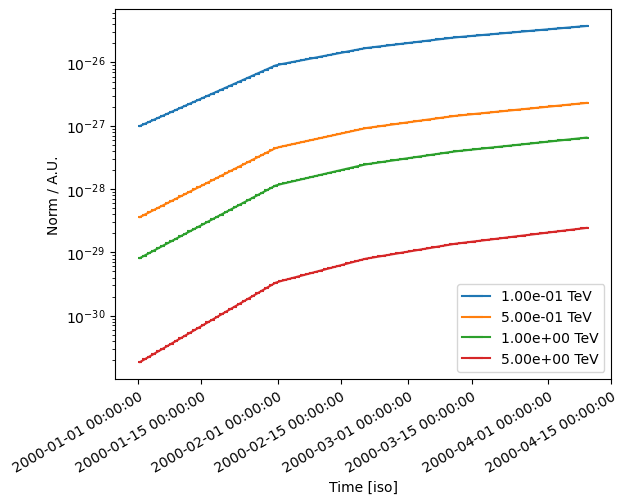

In [11]:
time_range = temporal_model.reference_time + [0, 100] * u.day

temporal_model.plot(time_range=time_range, energy=[0.1, 0.5, 1, 5] * u.TeV)
plt.legend()
plt.semilogy()
plt.show()